# Hidden Markov Models: Rachel infers Lily’s weather

A complete, runnable introduction using **hidden weather** and **observed activities**.

Rachel cannot see the weather where Lily lives. Each evening Lily reports one main activity: **Run**, **Office**, or **Clean**. Rachel uses those reports to estimate the weather and predict tomorrow.

**Key correction to the original example:** weather is hidden from Rachel; activities are observed. An ordinary Markov chain does not require hidden states. An HMM combines a hidden Markov chain with a probabilistic observation model. It is not a neural network.

### How to use this notebook
Run the cells from top to bottom in Jupyter Notebook, JupyterLab, VS Code, or Google Colab. Python 3 with NumPy and Matplotlib is sufficient. No dataset, account, network access during execution, or HMM library is needed. If imports fail, uncomment and run the installation line below once.

You will build the model, calculate Bayes’ rule by hand and in code, filter a sequence, decode a likely weather path with Viterbi, predict tomorrow, and try exercises with worked solutions. All probabilities are **invented teaching assumptions**, not measured weather data.

In [1]:
# If needed, uncomment this line, run it, then restart the kernel:
# %pip install numpy matplotlib
import itertools
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from IPython.display import display, Markdown
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})

## 1. States, observations, and assumptions

| Role | Symbol | Values | Known to Rachel? |
|---|---|---|---|
| Hidden weather on day $t$ | $Z_t$ | Sunny, Rainy | No |
| Reported activity on day $t$ | $O_t$ | Run, Office, Clean | Yes |

The integer codes below are array positions, not quantities or rankings.

We assume:
1. Tomorrow’s weather depends on today’s weather, not earlier weather once today is known: $P(Z_{t+1}\mid Z_{1:t})=P(Z_{t+1}\mid Z_t)$.
2. Today’s activity depends only on today’s weather, given that weather: $P(O_t\mid Z_{1:t},O_{1:t-1})=P(O_t\mid Z_t)$.
3. The probabilities stay constant over time, and Lily reports exactly one activity each day.

These simplify reality: work schedules, seasons, and personal preferences are ignored. “Hidden” means unobserved by Rachel, not unknowable or inherently mysterious.

State mapping: {'Sunny': 0, 'Rainy': 1}
Observation mapping: {'Run': 0, 'Office': 1, 'Clean': 2}


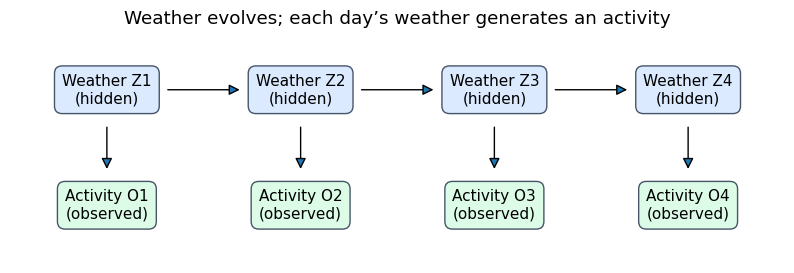

In [2]:
states = ['Sunny', 'Rainy']
activities = ['Run', 'Office', 'Clean']
state_to_id = {name: i for i, name in enumerate(states)}
activity_to_id = {name: i for i, name in enumerate(activities)}
print('State mapping:', state_to_id)
print('Observation mapping:', activity_to_id)

fig, ax = plt.subplots(figsize=(10, 3))
for t in range(4):
    for y, label, color in [(1, f'Weather Z{t+1}\n(hidden)', '#dbeafe'),
                            (0, f'Activity O{t+1}\n(observed)', '#dcfce7')]:
        ax.text(t, y, label, ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.5', fc=color, ec='#475569'))
    ax.add_patch(FancyArrowPatch((t, .70), (t, .29), arrowstyle='-|>', mutation_scale=16))
    if t < 3:
        ax.add_patch(FancyArrowPatch((t+.30, 1), (t+.70, 1), arrowstyle='-|>', mutation_scale=16))
ax.set(xlim=(-.5, 3.5), ylim=(-.5, 1.5), title='Weather evolves; each day’s weather generates an activity')
ax.axis('off')
plt.show()

## 2. The three probability ingredients

We use **row vectors** for distributions throughout.

- Initial distribution: $\pi_i=P(Z_1=i)$. Before any report, Sunny has probability 0.6.
- Transition matrix: $A_{ij}=P(Z_{t+1}=j\mid Z_t=i)$. Rows are **today**, columns **tomorrow**.
- Emission matrix: $B_{ik}=P(O_t=k\mid Z_t=i)$. Rows are **weather**, columns **activity**.

Every row sums to one. An emission is a likelihood of an activity given weather; it is **not** the probability of weather given that activity.

### Where do the values of π, A, and B come from?

**In this notebook, the values of $\pi$, $A$, and $B$ are supplied teaching assumptions.** They were chosen to illustrate how an HMM works, not inferred from data.

In real applications, these parameters can be estimated from historical data.

#### When historical weather and activities are both known

| Parameter | Meaning | How to estimate it |
|---|---|---|
| $\pi$ | Weather probabilities at the beginning of a sequence | Count how often each weather state starts a sequence, then normalise |
| $A$ | Probabilities of transitioning between weather states | Count transitions between consecutive days, then normalise each row |
| $B$ | Activity probabilities given each weather state | Count activities for each weather state, then normalise each row |

For example, suppose we observe **100 transitions starting from Sunny**:

- 80 transitions end in Sunny.
- 20 transitions end in Rainy.

We would estimate:

$$
P(\text{Sunny tomorrow}\mid\text{Sunny today})
=
\frac{80}{100}
=
0.8,
$$

$$
P(\text{Rainy tomorrow}\mid\text{Sunny today})
=
\frac{20}{100}
=
0.2.
$$

This gives the Sunny row of the transition matrix:

$$
A_{\text{Sunny},:}
=
\begin{bmatrix}
0.8 & 0.2
\end{bmatrix}.
$$

Similarly, if Lily runs on 60 out of 100 observed Sunny days, we would estimate:

$$
P(\text{Run}\mid\text{Sunny})
=
\frac{60}{100}
=
0.6.
$$

This gives one entry in the emission matrix $B$.

#### When only activities are observed

If the weather is hidden in the historical data too, we cannot directly count weather transitions or activities by weather state.

An algorithm called **Baum–Welch**, a form of *expectation–maximisation (EM)*, can estimate the parameters iteratively:

1. Start with initial guesses for $\pi$, $A$, and $B$.
2. Use the current model and observed activities to estimate probabilities of hidden states and transitions.
3. Update $\pi$, $A$, and $B$ using those estimated counts.
4. Repeat until a stopping criterion is reached.

The result can depend on the initial guesses and is not guaranteed to be the globally best model. Additional information is also needed to confidently label the learned hidden states as **Sunny** and **Rainy**; those meanings do not automatically emerge from activity data alone.

#### Learning the model versus using the model

- **Learning the model:** Estimate $\pi$, $A$, and $B$ from data.
- **Using the model:** Keep those parameters fixed and apply filtering or Viterbi to infer hidden weather.

**This notebook uses a supplied model.** Rachel's weather beliefs change with each report, but $\pi$, $A$, and $B$ remain fixed unless we explicitly change them in an exercise.

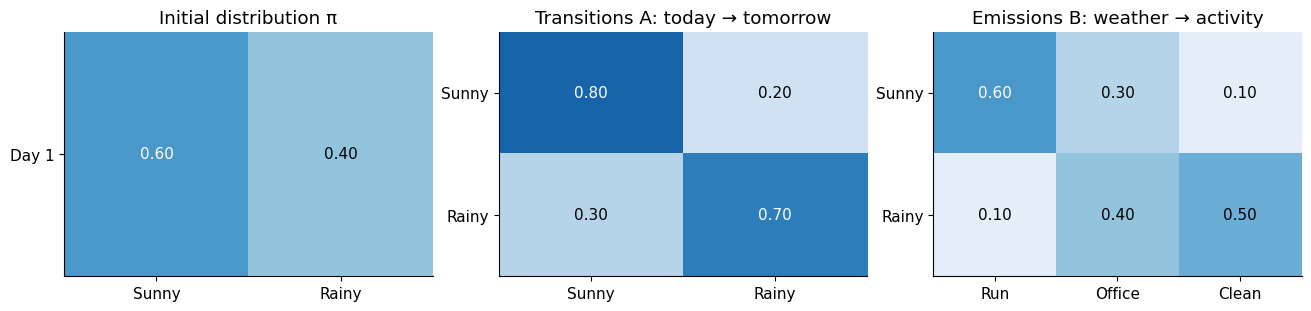

Example: P(Clean | Rainy) = 0.5


In [3]:
pi = np.array([0.60, 0.40])
A = np.array([[0.80, 0.20],
              [0.30, 0.70]])
B = np.array([[0.60, 0.30, 0.10],
              [0.10, 0.40, 0.50]])

def check_model(pi, A, B):
    n = len(pi)
    assert A.shape == (n, n) and B.shape[0] == n
    for values in (pi, A, B):
        assert np.all(np.isfinite(values)) and np.all(values >= 0)
    assert np.isclose(pi.sum(), 1)
    assert np.allclose(A.sum(axis=1), 1)
    assert np.allclose(B.sum(axis=1), 1)
check_model(pi, A, B)

def heatmap(ax, matrix, rows, columns, title):
    ax.imshow(matrix, cmap='Blues', vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(len(columns)), columns)
    ax.set_yticks(range(len(rows)), rows)
    ax.set_title(title)
    for i, j in np.ndindex(matrix.shape):
        ax.text(j, i, f'{matrix[i,j]:.2f}', ha='center', va='center',
                color='white' if matrix[i,j] > .55 else 'black')
fig, axes = plt.subplots(1, 3, figsize=(13, 3), constrained_layout=True)
heatmap(axes[0], pi[None, :], ['Day 1'], states, 'Initial distribution π')
heatmap(axes[1], A, states, states, 'Transitions A: today → tomorrow')
heatmap(axes[2], B, states, activities, 'Emissions B: weather → activity')
plt.show()
print('Example: P(Clean | Rainy) =', B[state_to_id['Rainy'], activity_to_id['Clean']])

## 3. One report: Bayes’ rule

Lily reports **Run** on day 1. Rachel combines the prior with the emission likelihood:

$$P(Z_1=i\mid O_1=\mathrm{Run})=
\frac{P(O_1=\mathrm{Run}\mid Z_1=i)P(Z_1=i)}{P(O_1=\mathrm{Run})}.$$


The two unnormalised weights are $0.6\times0.6=0.36$ for Sunny and $0.4\times0.1=0.04$ for Rainy. Their sum, 0.40, is the probability of seeing Run. Dividing gives **90% Sunny, 10% Rainy**. Running is evidence for sunshine, not proof.

Equations:

$$
\begin{aligned}
P(\text{Sunny and Run})
&= P(\text{Sunny})P(\text{Run}\mid\text{Sunny})
= 0.6 \times 0.6 = 0.36 \\
P(\text{Rainy and Run})
&= P(\text{Rainy})P(\text{Run}\mid\text{Rainy})
= 0.4 \times 0.1 = 0.04 \\
P(Run) &= P(\text{Sunny and Run}) + P(\text{Rainy and Run}) = 0.36 + 0.04 = 0.40 \\
P(Sunny \mid Run) &= \frac{P(\text{Sunny and Run})}{P(\text{Run})} = \frac{0.36}{0.4} = 0.9 = 90\% \\
P(Rainy \mid Run) &= \frac{P(\text{Rainy and Run})}{P(\text{Run})} = \frac{0.04}{0.4} = 0.1 = 10\%
\end{aligned}
$$

Prior: [0.6 0.4]
Likelihood P(Run | each weather): [0.6 0.1]
Evidence P(Run): 0.4
Posterior P(weather | Run): [0.9 0.1]


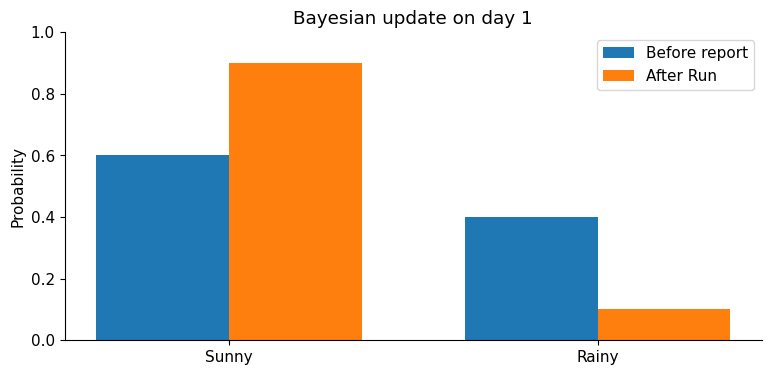

In [4]:
run = activity_to_id['Run']
weights = pi * B[:, run]
evidence = weights.sum()
posterior = weights / evidence
print('Prior:', pi)
print('Likelihood P(Run | each weather):', B[:, run])
print('Evidence P(Run):', evidence)
print('Posterior P(weather | Run):', posterior)
assert np.allclose(posterior, [.9, .1])
x = np.arange(len(states))
fig, ax = plt.subplots()
ax.bar(x-.18, pi, width=.36, label='Before report')
ax.bar(x+.18, posterior, width=.36, label='After Run')
ax.set(xticks=x, xticklabels=states, ylim=(0, 1), ylabel='Probability', title='Bayesian update on day 1')
ax.legend()
plt.show()

## 4. Forward filtering: update after each day

Now Rachel hears **Run, Office, Clean, Clean, Run** on five consecutive days.

Filtering estimates $f_t(i)=P(Z_t=i\mid O_{1:t})$ using reports available **up to that day**.

1. **Predict:** $q_1=\pi$; for later days, $q_t=f_{t-1}A$.
2. **Update:** $w_t(i)=q_t(i)B_{i,o_t}$.
3. **Normalise:** $c_t=\sum_i w_t(i)$ and $f_t=w_t/c_t$.

Here $c_t=P(O_t=o_t\mid O_{1:t-1})$. Therefore $P(O_{1:T})=\prod_t c_t$. We sum $\log c_t$ for numerical stability. This scaled forward algorithm avoids multiplying ever-smaller joint probabilities during filtering.

### Note: Why use logarithms?

Multiplying many probabilities can produce a number so small that the computer rounds it to zero (*numerical underflow*). Logarithms turn that product into a sum:

$$
\log P(O_{1:T}) = \sum_{t=1}^{T} \log c_t.
$$

For example, multiplying $0.1$ across 400 days gives $10^{-400}$, which underflows with standard floating-point numbers. Its natural logarithm, approximately $-921.03$, is easily represented.

Normalising the filtering weights each day keeps the weather probabilities summing to 1. Separately, summing $\log c_t$ preserves the sequence’s **log-likelihood** without multiplying increasingly tiny numbers. Neither step changes the underlying model.

In [5]:
def forward_filter(observation_ids, pi, A, B):
    """
    Estimate each day's weather using activity reports up to that day.

    This is forward filtering: predict today's weather, then update that
    prediction using today's reported activity. Future reports are not used.

    Parameters
    ----------
    observation_ids : sequence of integers
        Activity codes in chronological order.
        For example, [2, 2, 0] represents Clean, Clean, Run.

    pi : NumPy array of shape (n_states,)
        Weather probabilities before the first report.
        For example, [0.6, 0.4] represents 60% Sunny and 40% Rainy.

    A : NumPy array of shape (n_states, n_states)
        Transition probabilities.
        A[i, j] = probability of today's state j given yesterday's state i.

    B : NumPy array of shape (n_states, n_activities)
        Emission probabilities.
        B[i, k] = probability of activity k given weather state i.

    Returns
    -------
    predictions : NumPy array of shape (n_days, n_states)
        Weather probabilities BEFORE incorporating each day's report,
        but taking all earlier reports into account.

    filtered : NumPy array of shape (n_days, n_states)
        Weather probabilities AFTER incorporating each day's report.

    scales : NumPy array of shape (n_days,)
        Probability of each day's reported activity given earlier reports.
        These are the normalising constants used in the Bayesian updates.

    log_likelihood : float
        Natural logarithm of the probability of the entire report sequence
        under this model. Calculated by summing log(scales).

    Notes
    -----
    Weather columns follow the model's state order:
    column 0 = Sunny, column 1 = Rainy.

    Requires NumPy as np and the notebook's check_model() helper.
    Supply integer observation IDs; conversion to dtype=int below does
    not reject fractional inputs before converting them.
    """

    # Check that the model's arrays have compatible dimensions,
    # contain nonnegative finite probabilities, and sum appropriately to 1.
    check_model(pi, A, B)

    # Convert the supplied activity codes into a NumPy integer array.
    obs = np.asarray(observation_ids, dtype=int)

    # Require a one-dimensional, nonempty sequence of valid activity codes.
    # B.shape[1] is the number of activities: with 3 activities,
    # valid codes are 0, 1, and 2.
    if obs.ndim != 1 or len(obs) == 0 or np.any((obs < 0) | (obs >= B.shape[1])):
        raise ValueError('Supply a nonempty sequence of valid observation IDs.')

    # Collect one result per day:
    # - predictions: weather probabilities before today's report
    # - filtered: weather probabilities after today's report
    # - scales: probabilities of the reports themselves
    predictions, filtered, scales = [], [], []

    # Start with the initial weather distribution.
    # copy() creates a separate array without changing pi.
    belief = pi.copy()

    # Process reports in chronological order.
    # t=0 represents day 1; activity is that day's observed activity code.
    for t, activity in enumerate(obs):

        # STEP 1 — PREDICT today's weather before using today's report.
        #
        # On day 1, use pi directly: there is no earlier day to transition from.
        #
        # On later days, move yesterday's updated belief through A.
        # @ means matrix multiplication: it combines all possible
        # previous weather states and their transition probabilities.
        #
        # Example: if yesterday's belief was [0.9, 0.1], then
        # P(Sunny today) = 0.9 * 0.8 + 0.1 * 0.3 = 0.75.
        predicted = pi.copy() if t == 0 else belief @ A

        # STEP 2 — WEIGH each weather state using today's activity.
        #
        # B[:, activity] selects the activity's likelihood for every state.
        # For Run, this is [P(Run | Sunny), P(Run | Rainy)] = [0.6, 0.1].
        #
        # * means element-by-element multiplication, not matrix multiplication.
        # Each weight is:
        # P(weather today | earlier reports) * P(activity | weather today).
        #
        # These weights do not usually sum to 1 yet.
        weights = predicted * B[:, activity]

        # Add the weights to find the probability of today's activity,
        # given all earlier reports.
        #
        # On day 1 with Run:
        # scale = 0.6 * 0.6 + 0.4 * 0.1 = 0.40.
        scale = weights.sum()

        # If every weather state gives this report zero probability,
        # the model cannot explain it. Normalisation would divide by zero.
        if scale <= 0:
            raise ValueError('This observation sequence is impossible under the model.')

        # STEP 3 — NORMALISE using Bayes' rule.
        #
        # Divide each weight by their total to obtain updated weather
        # probabilities that sum to 1.
        #
        # On day 1 with Run:
        # belief = [0.36, 0.04] / 0.40 = [0.90, 0.10].
        #
        # This updated belief is used to predict the following day's weather.
        belief = weights / scale

        # Save today's prediction, updated belief, and report probability.
        predictions.append(predicted)
        filtered.append(belief)
        scales.append(scale)

    # Convert the daily normalising constants into a NumPy array.
    scales = np.asarray(scales)

    # The probability of the entire report sequence is the product of scales.
    # Sum their logarithms instead to avoid multiplying many tiny numbers.
    #
    # Return four results, in this order:
    # predictions, filtered probabilities, scales, and log-likelihood.
    return np.array(predictions), np.array(filtered), scales, np.log(scales).sum()

reports = ['Run', 'Office', 'Clean', 'Clean', 'Run']
obs = np.array([activity_to_id[a] for a in reports])
predicted, filtered, scales, log_likelihood = forward_filter(obs, pi, A, B)
print(f"{'Day':<5}{'Report':<10}{'Prior Sunny':>13}{'Posterior Sunny':>18}{'Posterior Rainy':>18}")
for t, report in enumerate(reports):
    print(f'{t+1:<5}{report:<10}{predicted[t,0]:>13.4f}{filtered[t,0]:>18.4f}{filtered[t,1]:>18.4f}')
print(f'Log probability of all reports: {log_likelihood:.6f}')
#print(f'Probability of all reports: {np.exp(log_likelihood):.8f}')
print(
    f'Probability of this exact activity sequence under the model: '
    f'{np.exp(log_likelihood):.8f}'
)
assert np.allclose(filtered.sum(axis=1), 1)

Day  Report      Prior Sunny   Posterior Sunny   Posterior Rainy
1    Run              0.6000            0.9000            0.1000
2    Office           0.7500            0.6923            0.3077
3    Clean            0.6462            0.2675            0.7325
4    Clean            0.4338            0.1329            0.8671
5    Run              0.3664            0.7763            0.2237
Log probability of all reports: -5.841838
Probability of this exact activity sequence under the model: 0.00290350


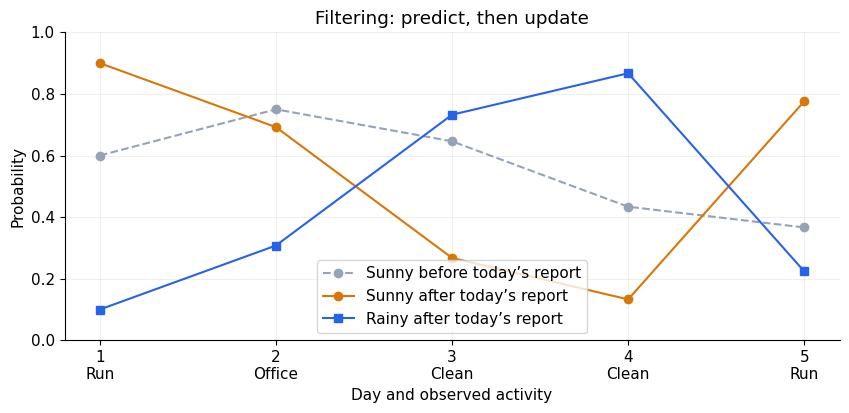

In [6]:
days = np.arange(1, len(obs)+1)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(days, predicted[:,0], 'o--', label='Sunny before today’s report', color='#94a3b8')
ax.plot(days, filtered[:,0], 'o-', label='Sunny after today’s report', color='#d97706')
ax.plot(days, filtered[:,1], 's-', label='Rainy after today’s report', color='#2563eb')
ax.set(xticks=days, xticklabels=[f'{d}\n{a}' for d,a in zip(days,reports)],
       ylim=(0,1), xlabel='Day and observed activity', ylabel='Probability', title='Filtering: predict, then update')
ax.legend(loc='best')
ax.grid(alpha=.2)
plt.show()

## 5. Viterbi: the most likely whole weather sequence

Filtering asks about a day given reports so far. **Viterbi decoding** asks which entire hidden path best explains **all five reports**:

$$z^*_{1:T}=\arg\max_{z_{1:T}} P(z_{1:T},o_{1:T}).$$

This also maximises the posterior path probability because $P(o_{1:T})$ is the same for every path. Viterbi uses a **maximum**, whereas forward inference **sums** over possible preceding states.

In log space:
$$\delta_1(j)=\log\pi_j+\log B_{j,o_1},$$
$$\delta_t(j)=\log B_{j,o_t}+\max_i[\delta_{t-1}(i)+\log A_{ij}].$$
Store the winning predecessor for each state, then backtrack. Choosing each day’s largest filtered probability does not generally produce the Viterbi path. Viterbi is also different from **smoothing**, which computes individual-day probabilities given all reports.

Viterbi path:			 Sunny → Rainy → Rainy → Rainy → Sunny
Daily filtered choices:	 Sunny → Sunny → Rainy → Rainy → Sunny
Joint probability of best path AND reports: 0.00063504
Posterior probability of best path GIVEN reports: 0.2187


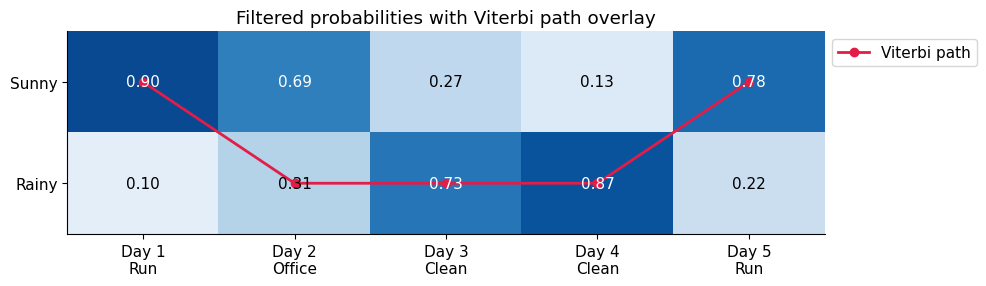

In [7]:
def viterbi(observation_ids, pi, A, B):
    check_model(pi, A, B)
    obs = np.asarray(observation_ids, dtype=int)
    if obs.ndim != 1 or len(obs) == 0 or np.any((obs < 0) | (obs >= B.shape[1])):
        raise ValueError('Supply a nonempty sequence of valid observation IDs.')
    # Zero probabilities become -infinity and cannot win a possible path.
    with np.errstate(divide='ignore'):
        log_pi, log_A, log_B = np.log(pi), np.log(A), np.log(B)
    scores = np.full((len(obs), len(pi)), -np.inf)
    back = np.zeros_like(scores, dtype=int)
    scores[0] = log_pi + log_B[:, obs[0]]
    for t in range(1, len(obs)):
        candidates = scores[t-1, :, None] + log_A
        back[t] = np.argmax(candidates, axis=0)
        scores[t] = candidates[back[t], np.arange(len(pi))] + log_B[:, obs[t]]
    path = np.zeros(len(obs), dtype=int)
    path[-1] = np.argmax(scores[-1])
    best_log_joint = scores[-1, path[-1]]
    if not np.isfinite(best_log_joint):
        raise ValueError('No possible hidden path for these observations.')
    for t in range(len(obs)-1, 0, -1):
        path[t-1] = back[t, path[t]]
    return path, best_log_joint

path, best_log_joint = viterbi(obs, pi, A, B)
print('Viterbi path:\t\t\t', ' → '.join(states[i] for i in path))
print('Daily filtered choices:\t', ' → '.join(states[i] for i in filtered.argmax(axis=1)))
print(f'Joint probability of best path AND reports: {np.exp(best_log_joint):.8f}')
print(f'Posterior probability of best path GIVEN reports: {np.exp(best_log_joint-log_likelihood):.4f}')
fig, ax = plt.subplots(figsize=(10, 3))
heatmap(ax, filtered.T, states, [f'Day {d}\n{a}' for d,a in zip(days,reports)], 'Filtered probabilities with Viterbi path overlay')
ax.plot(np.arange(len(obs)), path, 'o-', color='#e11d48', linewidth=2, label='Viterbi path')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

### Why does Viterbi choose Rainy on day 2?

The chart mixes two different results:

- **0.69 Sunny / 0.31 Rainy** are day 2’s *filtered probabilities*, using only **Run, Office**.
- The **Viterbi path** uses **all five reports**, including the two Clean reports that follow, to choose the most likely **whole weather sequence**.

We can compare two paths that differ only on day 2:

| Weather path | Probability of path **and all five reports** |
|---|---:|
| Sunny → **Sunny** → Rainy → Rainy → Sunny | 0.00054432 |
| Sunny → **Rainy** → Rainy → Rainy → Sunny | **0.00063504** |

Why does Rainy win? Holding day 1 Sunny and day 3 Rainy fixed, the factors affected by day 2 are shown below. Here, $S$ means Sunny and $R$ means Rainy.

$$
\begin{aligned}
\text{Sunny on day 2:}\quad
& P(S \to S)\,P(\text{Office}\mid S)\,P(S \to R) \\
&= 0.8 \times 0.3 \times 0.2 = 0.048 \\[6pt]
\text{Rainy on day 2:}\quad
& P(S \to R)\,P(\text{Office}\mid R)\,P(R \to R) \\
&= 0.2 \times 0.4 \times 0.7 = 0.056.
\end{aligned}
$$

All other factors are identical. So placing Rainy on day 2 makes this complete path more likely.

**Reading the chart:** The numbers underneath the Viterbi line are filtering probabilities, not Viterbi scores. Selecting the largest displayed number each day gives the daily filtered choices; it does not give the most likely whole path.

### Check the algorithms against every possible path
For five days and two states there are only $2^5=32$ weather paths. We can enumerate them to independently verify the forward likelihood and Viterbi result. Enumeration grows exponentially; the dynamic programming algorithms above take $O(TN^2)$ time for $N$ states.

In [8]:
def joint_probability(hidden_path, observation_ids, pi, A, B):
    probability = pi[hidden_path[0]] * B[hidden_path[0], observation_ids[0]]
    for t in range(1, len(observation_ids)):
        probability *= A[hidden_path[t-1], hidden_path[t]] * B[hidden_path[t], observation_ids[t]]
    return probability

all_paths = list(itertools.product(range(len(states)), repeat=len(obs)))
joints = np.array([joint_probability(p, obs, pi, A, B) for p in all_paths])
assert np.isclose(joints.sum(), np.exp(log_likelihood))
assert np.isclose(joints.max(), np.exp(best_log_joint))
assert np.isclose(joint_probability(path, obs, pi, A, B), joints.max())
# Also check each filtered posterior against independent prefix enumeration.
for t in range(len(obs)):
    masses = np.zeros(len(states))
    for p in itertools.product(range(len(states)), repeat=t+1):
        masses[p[-1]] += joint_probability(p, obs[:t+1], pi, A, B)
    assert np.allclose(filtered[t], masses / masses.sum())
print('Passed: forward likelihood, every filtered posterior, and Viterbi optimum match enumeration.')

Passed: forward likelihood, every filtered posterior, and Viterbi optimum match enumeration.


## 6. Predict tomorrow’s weather and activity

Use the full final filtered distribution, including uncertainty:

$$P(Z_{T+1}\mid o_{1:T})=f_T A,$$
$$P(O_{T+1}\mid o_{1:T})=(f_T A)B.$$

Tomorrow’s report has not arrived yet, so this is a prediction, not an update. Using only the last state on the Viterbi path would discard uncertainty.

  Sunny: 68.81%
  Rainy: 31.19%

    Run: 44.41%
 Office: 33.12%
  Clean: 22.47%



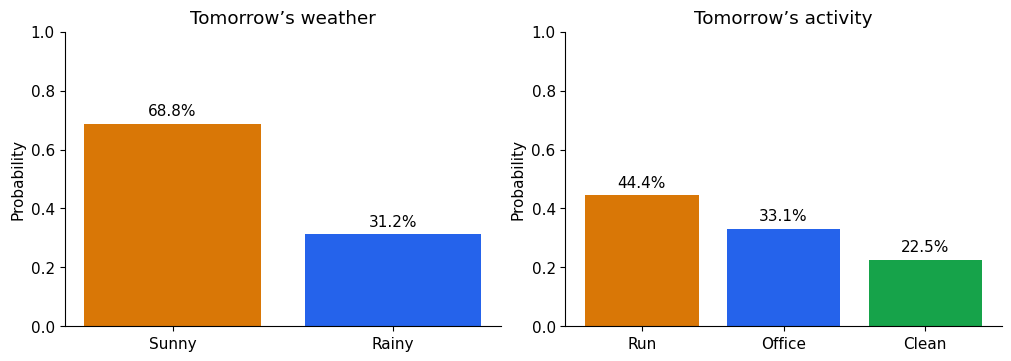

In [9]:
next_weather = filtered[-1] @ A
next_activity = next_weather @ B
for labels, probabilities in [(states, next_weather), (activities, next_activity)]:
    for label, probability in zip(labels, probabilities):
        print(f'{label:>7}: {probability:.2%}')
    print()
assert np.isclose(next_weather.sum(), 1) and np.isclose(next_activity.sum(), 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
for ax, labels, probabilities, title in zip(axes, [states, activities], [next_weather, next_activity],
                                           ['Tomorrow’s weather', 'Tomorrow’s activity']):
    bars = ax.bar(labels, probabilities, color=['#d97706', '#2563eb', '#16a34a'][:len(labels)])
    ax.bar_label(bars, labels=[f'{p:.1%}' for p in probabilities], padding=4)
    ax.set(ylim=(0,1), ylabel='Probability', title=title)
plt.show()

## 7. Simulate Lily’s world

In a simulation we know the true weather, so we can compare it with Rachel’s inference. Rachel’s algorithm still receives **activities only**. A fixed random seed makes this demonstration reproducible. Accuracy on one short, artificial sequence is illustrative, not evidence that the model describes real weather.

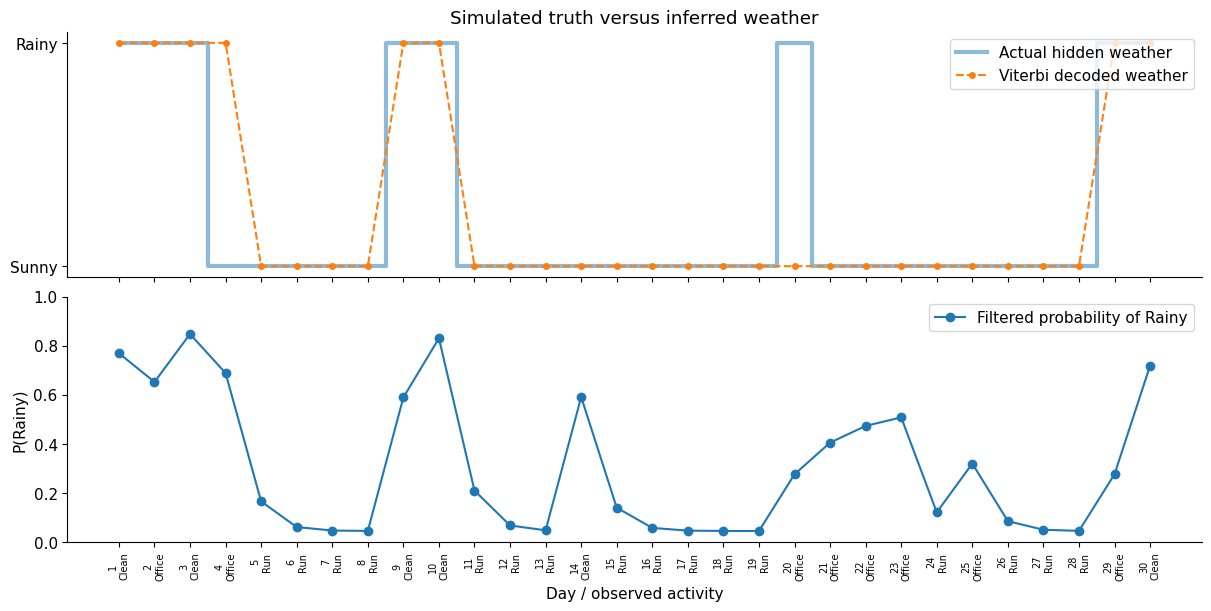

Viterbi accuracy on this simulation: 93.3%
Viterbi uses all 30 reports; filtering at day t uses only the first t reports.


In [10]:
def simulate_hmm(n_days, pi, A, B, seed=7):
    """
    Generate a sequence of hidden weather states and observed activities.

    Parameters
    ----------
    n_days : int
        Number of days to simulate; must be at least 1.
    pi : array of shape (n_states,)
        Initial weather probabilities, e.g. [0.6, 0.4].
    A : array of shape (n_states, n_states)
        Transition probabilities.
        A[i, j] = probability of tomorrow's state j given today's state i.
    B : array of shape (n_states, n_activities)
        Emission probabilities.
        B[i, k] = probability of activity k given weather state i.
    seed : int
        Makes the random simulation reproducible when inputs are unchanged.

    Returns
    -------
    hidden : integer array of shape (n_days,)
        Simulated weather codes: 0 = Sunny, 1 = Rainy.
    observed : integer array of shape (n_days,)
        Simulated activity codes: 0 = Run, 1 = Office, 2 = Clean.

    Assumes pi and each row of A and B are valid probability distributions.
    """

    # Create a local random-number generator.
    # A fixed seed lets us reproduce the same random draws.
    rng = np.random.default_rng(seed)

    # Allocate space for one weather code and one activity code per day.
    # np.empty does NOT initialise the values; we fill them below.
    hidden = np.empty(n_days, dtype=int)
    observed = np.empty(n_days, dtype=int)

    # Choose the first day's weather using the initial distribution pi.
    # rng.choice(len(pi), p=pi) samples a state code from 0 to len(pi)-1.
    # With pi = [0.6, 0.4], it chooses Sunny with probability 60%
    # and Rainy with probability 40%; it does not always choose Sunny.
    hidden[0] = rng.choice(len(pi), p=pi)

    # Array indices start at 0: t=0 represents day 1.
    for t in range(n_days):

        # On day 1, the weather was already chosen above.
        # For later days, choose weather based on the previous day's state.
        # "if t" is equivalent here to "if t > 0".
        if t:
            # Select the transition-matrix row for yesterday's weather.
            # For example, if yesterday was Rainy (code 1),
            # A[1] gives today's probabilities for [Sunny, Rainy].
            hidden[t] = rng.choice(len(pi), p=A[hidden[t-1]])

        # Choose today's activity based on today's simulated weather.
        # B.shape[1] is the number of possible activities (3).
        # B[hidden[t]] selects the emission row for today's weather.
        # For example, on a Sunny day, [0.6, 0.3, 0.1] gives
        # probabilities of 60% Run, 30% Office, and 10% Clean.
        observed[t] = rng.choice(B.shape[1], p=B[hidden[t]])

    # Return both sequences so we can compare inferred weather with truth.
    # Rachel's inference receives only "observed"; "hidden" is the
    # simulated ground truth, available to us for evaluating the result.
    return hidden, observed

truth, simulated_obs = simulate_hmm(30, pi, A, B)
_, simulated_filter, _, _ = forward_filter(simulated_obs, pi, A, B)
simulated_path, _ = viterbi(simulated_obs, pi, A, B)
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, constrained_layout=True)
sim_days = np.arange(1, len(truth)+1)
axes[0].step(sim_days, truth, where='mid', label='Actual hidden weather', linewidth=3, alpha=.5)
axes[0].plot(sim_days, simulated_path, 'o--', label='Viterbi decoded weather', markersize=4)
axes[0].set(yticks=[0,1], yticklabels=states, title='Simulated truth versus inferred weather')
axes[0].legend(loc='upper right')
axes[1].plot(sim_days, simulated_filter[:,1], 'o-', label='Filtered probability of Rainy')
axes[1].set(ylim=(0,1), ylabel='P(Rainy)', xlabel='Day / observed activity',
            xticks=sim_days, xticklabels=[f'{d}\n{activities[o]}' for d,o in zip(sim_days,simulated_obs)])
axes[1].tick_params(axis='x', labelsize=7, rotation=90)
axes[1].legend()
plt.show()
print(f'Viterbi accuracy on this simulation: {np.mean(simulated_path == truth):.1%}')
print('Viterbi uses all 30 reports; filtering at day t uses only the first t reports.')

## 8. Exercises

Try these before scrolling to the worked solutions. Use copies of arrays to keep the original example intact.

1. **Bayes:** If Lily reports Clean on day 1, calculate $P(\mathrm{Rainy}\mid\mathrm{Clean})$ by hand, then check in code.
2. **Sequence effects:** As per explanation below.
3. **Uninformative reports:** Set both emission rows to `[0.3, 0.4, 0.3]`. Does seeing an activity change that day’s predicted weather distribution?
4. **Weather persistence:** Replace $A$ with `[[0.95, 0.05], [0.05, 0.95]]`. Repeat the five-day filter and Viterbi decode. Explain why an isolated activity has less power to reverse a persistent weather model.
5. **Two-day forecast:** Predict the weather two days after the last report without observing anything new. Then predict the activity that day.
6. **Model criticism:** Name two missing real-world influences. Which assumption would each challenge?

### Exercise 2: Sequence effects

Compare these two separate scenarios:

| Scenario | Reports |
|---|---|
| A | Day 1: Clean → Day 2: Clean → Day 3: Run |
| B | Day 1: Run, with no earlier reports |

Use `forward_filter()` for each scenario. How does the probability of Sunny after the final Run in scenario A compare with the probability of Sunny after the only report in scenario B? Why?

**Note:** Scenario B is a separate hypothetical example. It does not replace the Clean report on day 1 of scenario A.

In [11]:
# Your workspace. Example:
# exercise_reports = ['Clean', 'Clean', 'Run']
# exercise_obs = [activity_to_id[a] for a in exercise_reports]
# ...

display(Markdown("**Hints for exercice 2**"))
# Convert the activity names into the integer codes the function expects.
exercise_reports = ['Clean', 'Clean', 'Run']
exercise_obs = [activity_to_id[a] for a in exercise_reports]


# Estimate each day's weather using the reports available up to that day.
'''_, exercise_filtered, _, _ = forward_filter(exercise_obs, pi, A, B)

for day, probabilities in enumerate(exercise_filtered, start=1):
    print(f"Day {day}: P(Sunny) = {probabilities[0]:.2%}")'''

exercice_predicted, exercise_filtered, _, _ = forward_filter(exercise_obs, pi, A, B)

def print_prior_and_posterior_results(reports, predicted, posterior_results):
    '''print(f"{'Day':<5}{'Report':<10}{'Prior Sunny':>13}{'Prior Rainy':>15}{'Posterior Sunny':>18}{'Posterior Rainy':>18}")
    for t, report in enumerate(reports):
        print(f"{t+1:<5}{report:<10}{predicted[t,0]:>13.2%}{predicted[t,1]:>15.2%}{posterior_results[t,0]:>18.2%}{posterior_results[t,1]:>18.2%}")'''
    print(f"{'Day':<5}{'Report':<10}{'Prior Sunny':>13}{'Posterior Sunny':>18}{'Prior Rainy':>15}{'Posterior Rainy':>18}")
    for t, report in enumerate(reports):
        print(f"{t+1:<5}{report:<10}{predicted[t,0]:>13.2%}{posterior_results[t,0]:>18.2%}{predicted[t,1]:>15.2%}{posterior_results[t,1]:>18.2%}")

print_prior_and_posterior_results(exercise_reports, exercice_predicted, exercise_filtered)

# Compare with hearing Run on day 1, with no earlier reports.
_, run_only_filtered, _, _ = forward_filter(
    [activity_to_id['Run']], pi, A, B
)

print(f"\nScenario A — Sunny on day 3 after Clean, Clean, Run: {exercise_filtered[-1, 0]:.2%}") # Last row, first column (Sunny)
print(f"Scenario B — Sunny on day 1 after only Run:          {run_only_filtered[0, 0]:.2%}")

**Hints for exercice 2**

Day  Report      Prior Sunny   Posterior Sunny    Prior Rainy   Posterior Rainy
1    Clean            60.00%            23.08%         40.00%            76.92%
2    Clean            41.54%            12.44%         58.46%            87.56%
3    Run              36.22%            77.31%         63.78%            22.69%

Scenario A — Sunny on day 3 after Clean, Clean, Run: 77.31%
Scenario B — Sunny on day 1 after only Run:          90.00%


In [12]:
# Exercice 3
print("Exercice 3")
val_1 = 0.3
val_2 = 0.4
val_3 = 1 - val_1 - val_2
B_exercice_three = np.array([[val_1, val_2, val_3],
              [val_1, val_2, val_3]])

print(f"B = \n{B_exercice_three}")

exercice_predicted, exercise_filtered, _, _ = forward_filter(exercise_obs, pi, A, B_exercice_three)
print_prior_and_posterior_results(exercise_reports, exercice_predicted, exercise_filtered)

# Exercice 3 Variation
# In both cases both rows are the same
print("\nExercice 3 variation")
val_1 = 0.01
val_2 = 0.01
val_3 = 1 - val_1 - val_2
B_exercice_three = np.array([[val_1, val_2, val_3],
              [val_1, val_2, val_3]])

print(f"B = \n{B_exercice_three}")

exercice_predicted, exercise_filtered, _, _ = forward_filter(exercise_obs, pi, A, B_exercice_three)
print_prior_and_posterior_results(exercise_reports, exercice_predicted, exercise_filtered)

Exercice 3
B = 
[[0.3 0.4 0.3]
 [0.3 0.4 0.3]]
Day  Report      Prior Sunny   Posterior Sunny    Prior Rainy   Posterior Rainy
1    Clean            60.00%            60.00%         40.00%            40.00%
2    Clean            60.00%            60.00%         40.00%            40.00%
3    Run              60.00%            60.00%         40.00%            40.00%

Exercice 3 variation
B = 
[[0.01 0.01 0.98]
 [0.01 0.01 0.98]]
Day  Report      Prior Sunny   Posterior Sunny    Prior Rainy   Posterior Rainy
1    Clean            60.00%            60.00%         40.00%            40.00%
2    Clean            60.00%            60.00%         40.00%            40.00%
3    Run              60.00%            60.00%         40.00%            40.00%


New A matrix =
[[0.95 0.05]
 [0.05 0.95]]
Day  Report      Prior Sunny   Posterior Sunny    Prior Rainy   Posterior Rainy
1    Run              60.00%            90.00%         40.00%            10.00%
2    Office           86.00%            82.17%         14.00%            17.83%
3    Clean            78.95%            42.86%         21.05%            57.14%
4    Clean            43.57%            13.38%         56.43%            86.62%
5    Run              17.04%            55.21%         82.96%            44.79%
Viterbi path: Sunny → Sunny → Sunny → Sunny → Sunny
Daily filtered choices: Sunny → Sunny → Rainy → Rainy → Sunny
Joint probability of best path AND reports: 0.00052780
Posterior probability of best path GIVEN reports: 0.3782


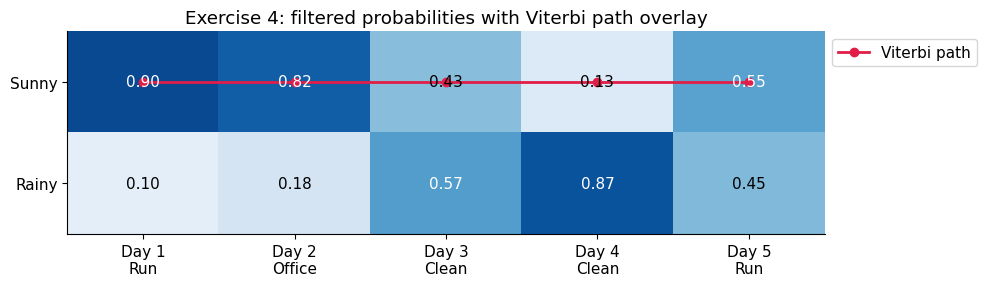

In [13]:
# Exercise 4: increase the probability of staying in the same weather.
p_stay = 0.95
A_exercise_four = np.array([
    [p_stay,     1 - p_stay],  # Sunny → [Sunny, Rainy]
    [1 - p_stay, p_stay]       # Rainy → [Sunny, Rainy]
])

print(f"New A matrix =\n{A_exercise_four}")

# Recalculate filtering AND the sequence likelihood with the new matrix.
predicted_four, filtered_four, scales_four, log_likelihood_four = (
    forward_filter(obs, pi, A_exercise_four, B)
)

print_prior_and_posterior_results(reports, predicted_four, filtered_four)


# Decode the most likely whole path using the same new matrix.
path_four, best_log_joint_four = viterbi(
    obs, pi, A_exercise_four, B
)

print(
    'Viterbi path:',
    ' → '.join(states[i] for i in path_four)
)

print(
    'Daily filtered choices:',
    ' → '.join(states[i] for i in filtered_four.argmax(axis=1))
)

print(
    f'Joint probability of best path AND reports: '
    f'{np.exp(best_log_joint_four):.8f}'
)

# Both numerator and denominator must come from the SAME model.
print(
    f'Posterior probability of best path GIVEN reports: '
    f'{np.exp(best_log_joint_four - log_likelihood_four):.4f}'
)

# Plot the updated filtering probabilities and updated Viterbi path.
fig, ax = plt.subplots(figsize=(10, 3))

heatmap(
    ax,
    filtered_four.T,
    states,
    [f'Day {d}\n{a}' for d, a in zip(days, reports)],
    'Exercise 4: filtered probabilities with Viterbi path overlay'
)

ax.plot(
    np.arange(len(obs)),
    path_four,
    'o-',
    color='#e11d48',
    linewidth=2,
    label='Viterbi path'
)

ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [14]:
# Exercice 5. Predictions after 2 days
exercice_predicted, exercise_filtered, _, _ = forward_filter(obs, pi, A, B)
print_prior_and_posterior_results(reports, exercice_predicted, exercise_filtered)

day_plus_1 = exercise_filtered[-1, :] @ A
day_plus_2 = day_plus_1 @ A

print(f"\nPrediction after 1 day (no reports) = {day_plus_1}. Verification: {day_plus_1.sum()}")
print(f"Prediction after 2 days (no reports) = = {day_plus_2}. Verification: {day_plus_2.sum()}")

def predict_after_n_days_with_no_reports(number_of_days, base_prediction, A):
    if base_prediction.ndim != 1:
        raise ValueError("base_prediction must be a 1D array.")

    if A.ndim != 2 or A.shape[0] != A.shape[1]:
        raise ValueError("A must be a square 2D transition matrix.")

    if base_prediction.shape[0] != A.shape[0]:
        raise ValueError(
            f"Incompatible dimensions: "
            f"base_prediction {base_prediction.shape} and A {A.shape}"
        )

    predictions = []
    for n in range(1, number_of_days):
        if n == 1:
            predictions.append(base_prediction @ A)
        else:
            predictions.append(predictions[-1] @ A)

    return predictions

predictions = predict_after_n_days_with_no_reports(10, exercise_filtered[-1, :], A)

def print_predictions_table(predictions):
    print(f"{'Day':<5}{'Sunny':>13}{'Rainy':>13}")

    for t, prediction in enumerate(predictions):
        print(f"{t+1:<5}{prediction[0]:>13.2%}{prediction[1]:>13.2%}")

print("\nRunning it over many days")
print_predictions_table(predictions)

Day  Report      Prior Sunny   Posterior Sunny    Prior Rainy   Posterior Rainy
1    Run              60.00%            90.00%         40.00%            10.00%
2    Office           75.00%            69.23%         25.00%            30.77%
3    Clean            64.62%            26.75%         35.38%            73.25%
4    Clean            43.38%            13.29%         56.62%            86.71%
5    Run              36.64%            77.63%         63.36%            22.37%

Prediction after 1 day (no reports) = [0.6881 0.3119]. Verification: 1.0
Prediction after 2 days (no reports) = = [0.6441 0.3559]. Verification: 1.0

Running it over many days
Day          Sunny        Rainy
1           68.81%       31.19%
2           64.41%       35.59%
3           62.20%       37.80%
4           61.10%       38.90%
5           60.55%       39.45%
6           60.28%       39.72%
7           60.14%       39.86%
8           60.07%       39.93%
9           60.03%       39.97%


it can be seen that the probabilities then to converge with the initial $\pi$ matrix probabilities.

In [15]:
# Exercice 5. Activity after 2 days
id_to_state = {i: name for i, name in enumerate(states)}
id_to_activity = {i: name for i, name in enumerate(activities)}

#print('State mapping:', id_to_state)
#print('Observation mapping:', id_to_activity)

highest_index_state = np.argmax(day_plus_2)
print(f"In 2 days is it more likely to be {id_to_state[highest_index_state]}")

print(f"\nProbabilities matrix:\n{B}")
'''print(f"\nProbabilities matrix for that weather: {B[highest_index_state]}")

highest_index_activity = np.argmax(B[highest_index_state])
print(f"\nProbabilities matrix for that activity: {B[highest_index_state][highest_index_activity]} which corresponds to {id_to_activity[highest_index_activity]}")'''

print("\nProbabilities after 2 days:")
# Combine activity probabilities across BOTH possible weather states,
# weighted by how likely each weather state is in two days.
two_day_activity = day_plus_2 @ B

for activity, probability in zip(activities, two_day_activity):
    print(f"{activity}: {probability:.2%}")

# Select the most likely activity AFTER accounting for weather uncertainty.
highest_index_activity = np.argmax(two_day_activity)

print(
    f"\nIn two days, the most likely activity is "
    f"{activities[highest_index_activity]} "
    f"({two_day_activity[highest_index_activity]:.2%})."
)

In 2 days is it more likely to be Sunny

Probabilities matrix:
[[0.6 0.3 0.1]
 [0.1 0.4 0.5]]

Probabilities after 2 days:
Run: 42.20%
Office: 33.56%
Clean: 24.24%

In two days, the most likely activity is Run (42.20%).


## 9. Worked solutions

### Solution 1: Bayes

The Rainy weight is $0.4×0.5=0.20$; the Sunny weight is $0.6×0.1=0.06$. Rainy’s posterior is $0.20/0.26≈0.7692$.

$$
\begin{aligned}
P(\text{Rainy and Clean})
&= P(\text{Rainy})P(\text{Clean}\mid\text{Rainy})
= 0.4 \times 0.5 = 0.2 \\
P(\text{Sunny and Clean})
&= P(\text{Sunny})P(\text{Clean}\mid\text{Sunny})
= 0.6 \times 0.1 = 0.06 \\
P(Clean) &= P(\text{Rainy and Clean}) + P(\text{Sunny and Clean}) = 0.2 + 0.06 = 0.26 \\
P(Rainy \mid Clean) &= \frac{P(\text{Rainy and Clean})}{P(\text{Clean})} = \frac{0.2}{0.26} = 0.76923077 ≈ 76.92\%
\end{aligned}
$$

### Solution 2: Sequence effects

| Scenario | Reports | Probability of Sunny after Run |
|---|---|---:|
| A | Day 1: Clean → Day 2: Clean → Day 3: Run | 77.31% |
| B | Day 1: Run, with no earlier reports | 90.00% |

In scenario A, the two earlier Clean reports favour Rainy. Because rainy weather tends to persist, Rachel assigns Sunny a probability of about **36.2%** before hearing the final Run report. Hearing Run increases it to **77.31%**.

In scenario B, there are no earlier reports. Rachel starts with the initial Sunny probability of **60%**, which increases to **90%** after hearing Run.

The same observation produces different posterior probabilities because Rachel starts with different prior probabilities.

**Equations for scenario B:**

$$
\begin{aligned}
P(\text{Sunny and Run})
&= P(\text{Sunny})P(\text{Run}\mid\text{Sunny})
= 0.6 \times 0.6 = 0.36 \\
P(\text{Rainy and Run})
&= P(\text{Rainy})P(\text{Run}\mid\text{Rainy})
= 0.4 \times 0.1 = 0.04 \\
P(Run) &= P(\text{Sunny and Run}) + P(\text{Rainy and Run}) = 0.36 + 0.04 = 0.40 \\
P(Sunny \mid Run) &= \frac{P(\text{Sunny and Run})}{P(\text{Run})} = \frac{0.36}{0.4} = 0.9 = 90\%
\end{aligned}
$$

### Solution 3: Uninformative reports

Identical emission rows make the report uninformative about weather. Both weather probabilities are multiplied by the same number, which cancels during normalisation.

### Solution 4: Weather persistence

Increasing both self-transition probabilities to **0.95** makes the model expect weather to persist: a Sunny day is likely to be followed by another Sunny day, and likewise for Rainy.

With the reports **Run → Office → Clean → Clean → Run**, the Viterbi path becomes **Sunny → Sunny → Sunny → Sunny → Sunny**. Although Clean is more likely on a rainy day, it is still possible on a sunny day. Under the new matrix, remaining Sunny throughout gives a higher whole-path probability than switching to Rainy and back.

This does **not** mean the model is certain that every day was Sunny. Filtering still favours Rainy on days 3 and 4, using the reports available up to each day. Viterbi instead selects the single most likely complete path using all five reports.

Enough evidence favouring Rainy can still change the decoded path; the higher self-transition probabilities make weather changes less likely, not impossible.

**Implementation reminder:** Recalculate both filtering and Viterbi with the new transition matrix. The heatmap and the posterior probability of the decoded path must also use results from that same updated model.

### Solution 5: Predict the weather and activity two days ahead

We want to predict what happens **two days after the last report**, without receiving any new reports.

After observing **Run → Office → Clean → Clean → Run**, the final filtered weather distribution is approximately:

$$
f_5 =
\begin{bmatrix}
P(\text{Sunny}\mid O_{1:5}) &
P(\text{Rainy}\mid O_{1:5})
\end{bmatrix}
=
\begin{bmatrix}
0.7763 & 0.2237
\end{bmatrix}.
$$

#### 1. Predict the weather two days ahead

The transition matrix is:

$$
A =
\begin{bmatrix}
0.8 & 0.2 \\
0.3 & 0.7
\end{bmatrix}.
$$

Multiplying by $A$ once predicts the next day's weather:

$$
q_6 = f_5 A
\approx
\begin{bmatrix}
0.7763(0.8) + 0.2237(0.3) &
0.7763(0.2) + 0.2237(0.7)
\end{bmatrix}
\approx
\begin{bmatrix}
0.6881 & 0.3119
\end{bmatrix}.
$$

Multiplying by $A$ again predicts the weather two days ahead:

$$
q_7 = q_6 A = f_5 A^2
\approx
\begin{bmatrix}
0.6441 & 0.3559
\end{bmatrix}.
$$

Here, $A^2$ means the matrix product $A A$, not squaring each entry.

Therefore, the weather forecast for day 7 is:

| Weather | Probability |
|---|---:|
| Sunny | **64.41%** |
| Rainy | **35.59%** |

#### 2. Predict the activity two days ahead

The emission matrix gives activity probabilities conditional on weather:

$$
B =
\begin{bmatrix}
0.6 & 0.3 & 0.1 \\
0.1 & 0.4 & 0.5
\end{bmatrix}.
$$

Its rows are **Sunny, Rainy**, and its columns are **Run, Office, Clean**.

We must account for **both possible weather states**, weighted by their predicted probabilities. For each activity $a$:

$$
P(O_7=a\mid O_{1:5})
=
\sum_{z\in\{\text{Sunny},\text{Rainy}\}}
P(Z_7=z\mid O_{1:5})\,P(O_7=a\mid Z_7=z).
$$

Using the rounded weather probabilities:

$$
\begin{aligned}
P(\text{Run on day 7}\mid O_{1:5})
&\approx 0.6441(0.6) + 0.3559(0.1)
\approx 0.4220, \\[6pt]
P(\text{Office on day 7}\mid O_{1:5})
&\approx 0.6441(0.3) + 0.3559(0.4)
\approx 0.3356, \\[6pt]
P(\text{Clean on day 7}\mid O_{1:5})
&\approx 0.6441(0.1) + 0.3559(0.5)
\approx 0.2424.
\end{aligned}
$$

Matrix multiplication performs all three calculations at once:

$$
P(O_7\mid O_{1:5}) = q_7 B = f_5 A^2 B
\approx
\begin{bmatrix}
0.4220 & 0.3356 & 0.2424
\end{bmatrix}.
$$

| Activity | Probability |
|---|---:|
| Run | **42.20%** |
| Office | **33.56%** |
| Clean | **24.24%** |

**Run is the most likely activity**, with a probability of approximately **42.20%**.

Selecting only Sunny and using its emission row would give $P(\text{Run}\mid\text{Sunny})=60\%$. That assumes Sunny weather. Our forecast instead includes the **35.59% chance of Rainy weather**, so it preserves uncertainty about the weather.

### Solution 6: Weather persistence

A weekday work schedule challenges the assumption that activity depends only on weather. Seasonality challenges constant initial/transition/emission assumptions; a longer weather memory challenges the first-order Markov assumption. Model parameters here are supplied, not learned. Learning them from data is a separate topic, often approached with Baum–Welch (an EM algorithm).

In [16]:
# 1
clean_weights = pi * B[:, activity_to_id['Clean']]
print('1. Posterior [Sunny, Rainy] after Clean:', clean_weights / clean_weights.sum())
# 2
exercise_obs = [activity_to_id[a] for a in ['Clean', 'Clean', 'Run']]
_, exercise_filtered, _, _ = forward_filter(exercise_obs, pi, A, B)
print('2. Sunny after Clean, Clean, Run:', exercise_filtered[-1,0])
print('   Sunny after a first-day Run:', posterior[0])
# 3
uninformative_B = np.array([[.3,.4,.3], [.3,.4,.3]])
uninformative_prior, uninformative_filter, _, _ = forward_filter(obs, pi, A, uninformative_B)
assert np.allclose(uninformative_prior, uninformative_filter)
print('3. Reports leave each predicted distribution unchanged:', True)
# 4
persistent_A = np.array([[.95,.05], [.05,.95]])
_, persistent_filter, _, _ = forward_filter(obs, pi, persistent_A, B)
persistent_path, _ = viterbi(obs, pi, persistent_A, B)
print('4. Original Sunny probabilities:  ', filtered[:,0])
print('   Persistent Sunny probabilities:', persistent_filter[:,0])
print('   Persistent Viterbi path:', [states[i] for i in persistent_path])
# 5
two_day_weather = filtered[-1] @ np.linalg.matrix_power(A, 2)
two_day_activity = two_day_weather @ B
print('5. Two-day weather:', dict(zip(states, two_day_weather.round(4))))
print('   Two-day activity:', dict(zip(activities, two_day_activity.round(4))))

1. Posterior [Sunny, Rainy] after Clean: [0.2308 0.7692]
2. Sunny after Clean, Clean, Run: 0.7731147540983606
   Sunny after a first-day Run: 0.8999999999999999
3. Reports leave each predicted distribution unchanged: True
4. Original Sunny probabilities:   [0.9    0.6923 0.2675 0.1329 0.7763]
   Persistent Sunny probabilities: [0.9    0.8217 0.4286 0.1338 0.5521]
   Persistent Viterbi path: ['Sunny', 'Sunny', 'Sunny', 'Sunny', 'Sunny']
5. Two-day weather: {'Sunny': 0.6441, 'Rainy': 0.3559}
   Two-day activity: {'Run': 0.422, 'Office': 0.3356, 'Clean': 0.2424}


## Takeaways

| Question | Calculation |
|---|---|
| What weather is plausible before the first report? | Initial distribution $\pi$ |
| How can weather change? | Transition matrix $A$ |
| How likely is an activity given weather? | Emission matrix $B$ |
| What is today’s weather given reports so far? | Forward filtering |
| What whole weather path best explains all reports? | Viterbi decoding |
| What might happen tomorrow? | Filtered distribution $\times A$, then $\times B$ |

Weather is hidden; activities are observed. The observation model connects them probabilistically, and inference preserves uncertainty rather than treating an activity as a certain weather label.